# **Теория №1. Основные методы OpenCV (Часть №1)**

Официальная документация: https://docs.opencv.org/4.x/d6/d00/tutorial_py_root.html

---

## **1. Чтение, запись и отображение**

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

### **Чтение изображений**

В библиотеке OpenCV для Python открытие изображений может быть выполнено с использованием различных режимов, которые определяются через флаги, передаваемые функции `cv2.imread()`. Вот некоторые из наиболее распространенных флагов и их значения:

1. `cv2.IMREAD_COLOR`: Это значение по умолчанию, оно обозначается числом `1`. Изображение загружается в цветном режиме. Если в исходном изображении была прозрачность, она игнорируется. Эквивалентное числовое значение для этого режима: `1`.

2. `cv2.IMREAD_GRAYSCALE`: Загружает изображение в оттенках серого. Это режим можно также указать, используя значение `0`. Все цветовые каналы усредняются или взвешиваются для получения одного канала серого. Эквивалентное числовое значение для этого режима: `0`.

3. `cv2.IMREAD_UNCHANGED`: Изображение загружается включая альфа-канал, если он присутствует. Это значит, что прозрачность будет сохранена. Этот режим имеет числовое значение `-1`.

Это основные флаги, но есть и специфические, которые могут быть полезны в некоторых случаях:

- `cv2.IMREAD_ANYCOLOR`: Загрузка изображения в любом возможном цветовом формате.
- `cv2.IMREAD_ANYDEPTH`: Загрузка изображения с любой возможной глубиной битов (например, 16-битовое изображение будет загружено как есть).
- `cv2.IMREAD_LOAD_GDAL`: Использовать библиотеку GDAL для загрузки изображения.

Для загрузки изображения в обычном цветном режиме без изменения, можно не указывать никаких флагов или явно передать `cv2.IMREAD_COLOR`.

#### **Работа с локальным изображением**

##### **Загрузка изображения в локальное хранилище**

In [ ]:
# Ссылка на файл для скачивания
url = r'https://2spalnika.ru/wp-content/uploads/2022/12/zhivotniy-mir-hibin-800x600.jpg'

# Скачиваем файл с помощью wget
!wget -O arctic_fox.jpg '{url}'

--2026-09-08 10:40:03--  https://2spalnika.ru/wp-content/uploads/2022/12/zhivotniy-mir-hibin-800x600.jpg
Resolving 2spalnika.ru (2spalnika.ru)... 87.236.16.233
Connecting to 2spalnika.ru (2spalnika.ru)|87.236.16.233|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 105772 (103K) [image/jpeg]
Saving to: ‘arctic_fox.jpg’

arctic_fox.jpg      100%[===================>] 103.29K   135KB/s    in 0.8s    

2026-09-08 10:40:06 (135 KB/s) - ‘arctic_fox.jpg’ saved [105772/105772]



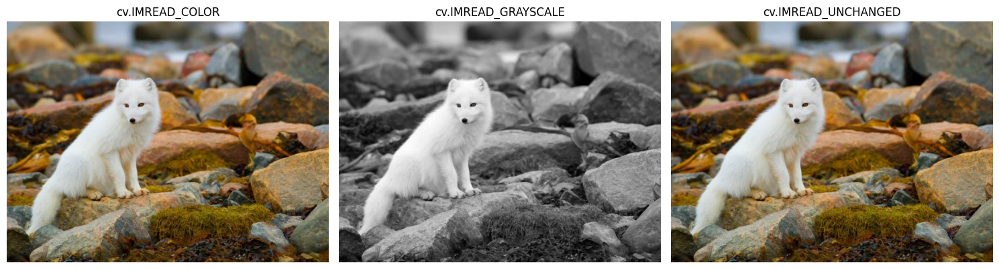

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt

# Путь к изображению
image_path = 'arctic_fox.jpg'

# Загрузка изображений
img_color = cv.imread(image_path, cv.IMREAD_COLOR)
img_gray = cv.imread(image_path, cv.IMREAD_GRAYSCALE)
img_unchanged = cv.imread(image_path, cv.IMREAD_UNCHANGED)

# Создание фигуры для отображения
plt.figure(figsize=(15, 5))

# Отображение цветного изображения
img_color_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)
plt.subplot(1, 3, 1)
plt.imshow(img_color_rgb)
plt.title('cv.IMREAD_COLOR')
plt.axis('off')

# Отображение изображения в оттенках серого
plt.subplot(1, 3, 2)
plt.imshow(img_gray, cmap='gray')
plt.title('cv.IMREAD_GRAYSCALE')
plt.axis('off')

# Отображение изображения без изменений
plt.subplot(1, 3, 3)
if len(img_unchanged.shape) == 2:
    plt.imshow(img_unchanged, cmap='gray')
elif img_unchanged.shape[2] == 4:
    img_unchanged_rgba = cv.cvtColor(img_unchanged, cv.COLOR_BGRA2RGBA)
    plt.imshow(img_unchanged_rgba)
else:
    img_unchanged_rgb = cv.cvtColor(img_unchanged, cv.COLOR_BGR2RGB)
    plt.imshow(img_unchanged_rgb)
plt.title('cv.IMREAD_UNCHANGED')
plt.axis('off')

plt.tight_layout()
plt.show()

#### **Работа с изображением из сети Интернет**

В данном примере мы загружаем изображение в оперативную память устройства, не сохраняя его в локальное хранилище

In [ ]:
# Импортируем модуль requests для выполнения HTTP запросов
import requests
# Импортируем класс BytesIO для работы с байтами как с файлом
from io import BytesIO

# URL адрес изображения, с которого будет произведена загрузка
url = r'https://2spalnika.ru/wp-content/uploads/2022/12/zhivotniy-mir-hibin-800x600.jpg'

# Выполнение HTTP GET запроса к URL, получение ответа как потока байтов
# Тем самым мы избегаем загрузки всего содержимого в память сразу
# Использование атрибута 'raw' позволяет получить необработанный поток данных
resp = requests.get(url, stream=True).raw


# Преобразуем данные, прочитанные из потока resp.read() (набор байтов),
# в одномерный массив NumPy с типом элементов 'uint8' (unsigned integer 8 bits).
img = np.asarray(bytearray(resp.read()), dtype="uint8")


# Декодируем массив байтов в изображение с помощью функции imdecode.
# IMREAD_COLOR говорит о том, что изображение будет преобразовано в цветное с каналами BGR.
img = cv.imdecode(img, cv.IMREAD_COLOR)
orig_image = img.copy()

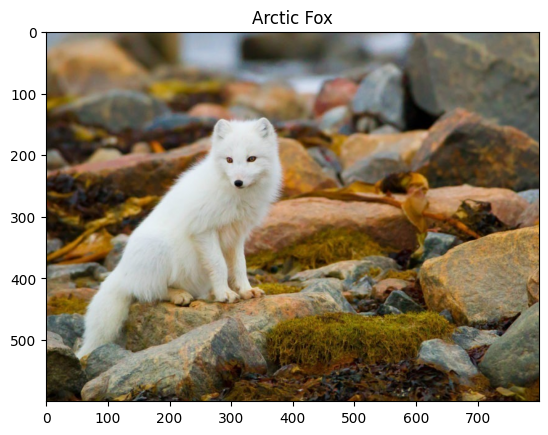

In [ ]:
# Функция cv.cvtColor преобразует цветовое пространство изображения из BGR (используемого OpenCV)
# в RGB, которое используется для отображения изображений в matplotlib.
# plt.imshow отображает преобразованное изображение.

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))

plt.title("Arctic Fox")  # Добавляет заголовок "Arctic Fox" к текущему изображению.

plt.show()  # Отображает изображение с заголовком.

### **Вывод основной информации об изображении**

In [ ]:
## Вывод размерности изображения
img.shape

(600, 800, 3)

In [ ]:
# Форматный вывод основной информации об изображении
import cv2 as cv

# Загрузка изображения
image_path = '/content/arctic_fox.jpg'
img = cv.imread(image_path, cv.IMREAD_UNCHANGED)

# Проверка успешности загрузки
if img is None:
    print("Не удалось загрузить изображение.")
else:
    # Размеры изображения
    height, width = img.shape[:2]
    print(f"Размеры изображения: {width}x{height} пикселей")

    # Количество каналов
    if len(img.shape) == 2:
        print("Изображение в градациях серого (1 канал)")
    else:
        channels = img.shape[2]
        print(f"Количество каналов: {channels}")

    # Тип данных пикселей
    print(f"Тип данных пикселей: {img.dtype}")

    # Минимальное и максимальное значения пикселей
    min_value = img.min()
    max_value = img.max()
    print(f"Мин. значение пикселя: {min_value}")
    print(f"Макс. значение пикселя: {max_value}")

    # Среднее значение и стандартное отклонение пикселей
    mean_value = img.mean()
    std_dev = img.std()
    print(f"Среднее значение пикселей: {mean_value:.2f}")
    print(f"Стандартное отклонение пикселей: {std_dev:.2f}")


Размеры изображения: 800x600 пикселей
Количество каналов: 3
Тип данных пикселей: uint8
Мин. значение пикселя: 0
Макс. значение пикселя: 249
Среднее значение пикселей: 103.80
Стандартное отклонение пикселей: 57.54


### **Сохранение изображения**

Метод `cv.imwrite` из библиотеки OpenCV используется для сохранения изображения в файл.

**Синтаксис:**

```python
cv.imwrite(filename, img, params=None)
```

**Параметры:**
- `filename`: строка с именем файла и путем сохранения. Расширение файла определяет формат изображения (например, `.jpg`, `.png`).
- `img`: изображение в виде массива NumPy, которое нужно сохранить.
- `params`: список дополнительных параметров в виде пар `[paramId, value]` (необязательный).

**Примеры:**

1. **Сохранение изображения без дополнительных настроек:**

```python
   cv.imwrite('output.jpg', img)
   ```

2. **Сохранение изображения с настройкой качества для JPEG:**

```python
   cv.imwrite('output.jpg', img, [cv.IMWRITE_JPEG_QUALITY, 90])  # Качество от 0 до 100
   ```

3. **Сохранение изображения с настройкой степени сжатия для PNG:**

```python
   cv.imwrite('output.png', img, [cv.IMWRITE_PNG_COMPRESSION, 9])  # Сжатие от 0 до 9
   ```

**Основные параметры `params`:**
- **Для JPEG:**
  - `cv.IMWRITE_JPEG_QUALITY`: качество сжатия от 0 до 100 (по умолчанию 95).
- **Для PNG:**
  - `cv.IMWRITE_PNG_COMPRESSION`: степень сжатия от 0 до 9 (по умолчанию 3).

**Возвращаемое значение:**
- Возвращает `True`, если изображение успешно сохранено, и `False` в случае ошибки.

**Пример:**

In [ ]:
# Сохранение изображения
cv.imwrite('arctic_fox.jpg', img)

True

## **2. Работа с цветовыми пространствами**

Функция `cv.cvtColor` используется в библиотеке компьютерного зрения OpenCV для Python, чтобы изменить цветовое пространство изображения. Синтаксис функции следующий:

```python
dst = cv.cvtColor(src, code, dstCn)
```

- **src**: Входное изображение; это исходный массив изображения, который должен быть 8-битным, 16-битным беззнаковым (unsigned) или 32-битным с плавающей точкой.
- **code**: Код цветового пространства преобразования. Этот код указывает, каким образом должно измениться цветовое пространство. Например, `cv.COLOR_BGR2GRAY` переведет изображение из BGR (используемого по умолчанию в OpenCV) в оттенки серого.
- **dstCn**: Количество каналов в выходном изображении; если параметр равен 0, количество каналов будет взято из src и кода.

Пример использования:

```python
import cv2 as cv

# Загрузим цветное изображение в формате BGR
img = cv.imread('path_to_image.jpg')

# Преобразуем изображение из BGR в оттенки серого
gray_img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

```

В этом примере мы загрузили изображение, применили к нему функцию `cv.cvtColor` для преобразования в градации серого и затем отобразили исходное и преобразованное изображения.

Количество различных преобразований основано на различных кодах, которые можно передать функции `cv.cvtColor`. Некоторые распространенные примеры кодов преобразования цветов:

- `cv.COLOR_BGR2GRAY`: BGR в оттенки серого
- `cv.COLOR_GRAY2BGR`: Оттенки серого в BGR
- `cv.COLOR_BGR2RGB`: BGR в RGB
- `cv.COLOR_RGB2GRAY`: RGB в оттенки серого
- `cv.COLOR_BGR2HSV`: BGR в HSV (оттенок, насыщенность, значение)
- И многие другие...

### **Преобразование изображения в оттенки серого**

Преобразование цветного изображения в оттенки серого является одной из основных операций в области обработки изображений и компьютерного зрения. Это преобразование упрощает изображение, удаляя цветовую информацию и сохраняя только яркостные характеристики, что облегчает дальнейший анализ и обработку.

#### **Цветовые пространства и представление изображений**

В OpenCV цветные изображения обычно представлены в цветовом пространстве **BGR** (Blue, Green, Red), где каждый пиксель содержит три компонента, соответствующие синему, зеленому и красному каналам.

Изображение в оттенках серого является **одно-канальным** (монохромным), где каждый пиксель содержит только значение яркости, обычно в диапазоне от 0 (черный) до 255 (белый) для 8-битных изображений.

#### **Принцип преобразования в оттенки серого**

При преобразовании цветного изображения в оттенки серого необходимо преобразовать трехканальное изображение (BGR) в одно-канальное, вычислив яркость каждого пикселя на основе его цветовых компонент.

Стандартная формула для вычисления яркости с учетом восприимчивости человеческого глаза к разным цветам:

$
\text{Y} = 0.114 \times B + 0.587 \times G + 0.299 \times R
$

- **R** — интенсивность красного канала.
- **G** — интенсивность зеленого канала.
- **B** — интенсивность синего канала.
- **Y** — вычисленное значение яркости (оттенок серого).

Эти коэффициенты характеризуют, что человеческий глаз наиболее чувствителен к зеленому цвету, затем к красному и наименее чувствителен к синему.

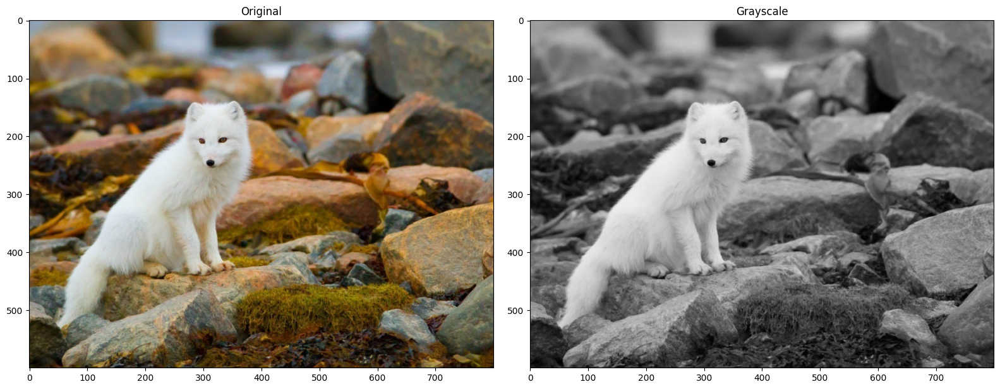

In [ ]:
gray_image = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
fig.tight_layout()

ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax[0].set_title("Original")

ax[1].imshow(cv.cvtColor(gray_image, cv.COLOR_GRAY2RGB))
ax[1].set_title("Grayscale")
plt.show()

#### **Альтернативные методы преобразования**

##### **Усреднение цветовых каналов**

Простой, но менее точный метод — усреднение значений трех каналов:

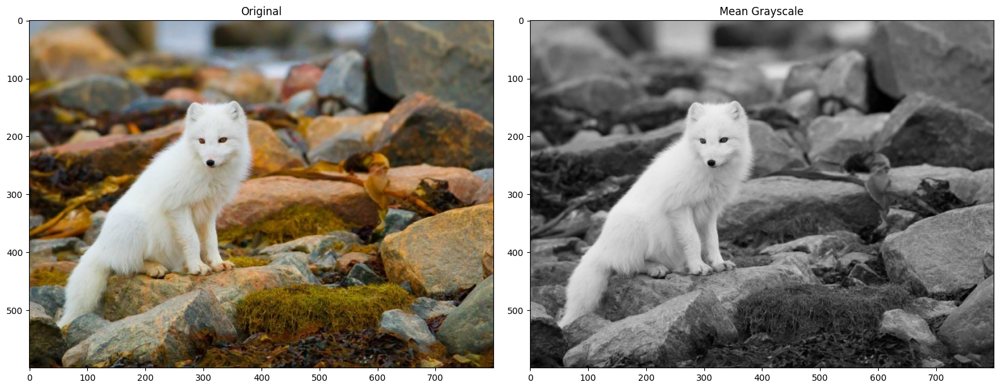

In [ ]:
import numpy as np

gray_image_simple = np.mean(img, axis=2).astype(np.uint8)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
fig.tight_layout()

ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax[0].set_title("Original")

ax[1].imshow(cv.cvtColor(gray_image_simple, cv.COLOR_GRAY2RGB))
ax[1].set_title("Mean Grayscale")
plt.show()

Этот метод не учитывает разную чувствительность глаз к цветам и может дать менее реалистичные результаты.

##### **Выбор одного из каналов**

Иногда может быть полезно использовать один из цветовых каналов в качестве изображения в оттенках серого:

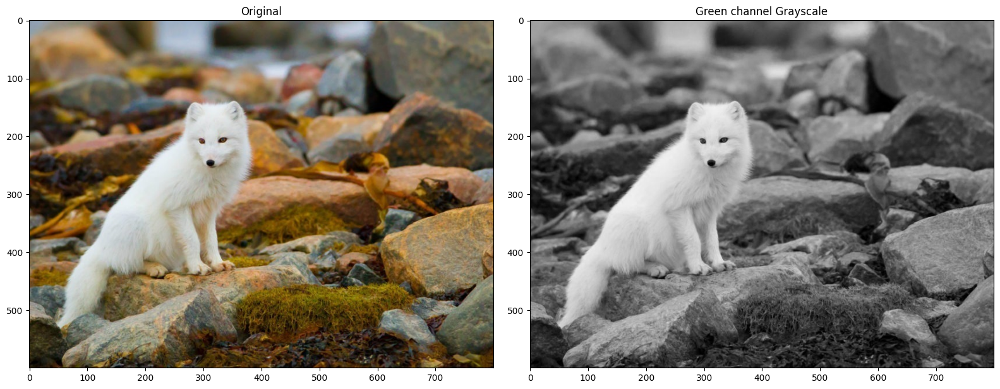

In [ ]:
# Использование зеленого канала
green_channel = img[:, :, 1]

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
fig.tight_layout()

ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax[0].set_title("Original")

ax[1].imshow(cv.cvtColor(green_channel, cv.COLOR_GRAY2RGB))
ax[1].set_title("Green channel Grayscale")
plt.show()

### **Цветовое пространство HSV**

HSV (Hue, Saturation, Value — оттенок, насыщенность, значение) — цветовое пространство, в котором цвет описывается через оттенок, насыщенность и уровень светлоты. Такое представление удобно, когда необходимо независимо работать с цветовым тоном и его выраженностью.

#### **Оттенок (Hue)**

Оттенок задаёт положение цвета на цветовом круге. В теоретической модели используется угол от 0° до 360°: красный соответствует области около 0°, зелёный — около 120°, синий — около 240°.

#### **Насыщенность (Saturation)**

Насыщенность показывает, насколько цвет отличается от серого. При нулевой насыщенности цвет становится ахроматическим, а при увеличении насыщенности цветовой тон выражен сильнее. Степень затемнения определяется компонентом Value, а не Saturation.

#### **Значение (Value)**

Value описывает уровень светлоты: минимальное значение соответствует чёрному, максимальное — наиболее светлому варианту данного цвета.

В OpenCV для обычного 8-битного HSV-изображения канал H хранится в диапазоне 0–179, а каналы S и V — в диапазоне 0–255. Поэтому значения массива OpenCV не следует напрямую интерпретировать как градусы и проценты.

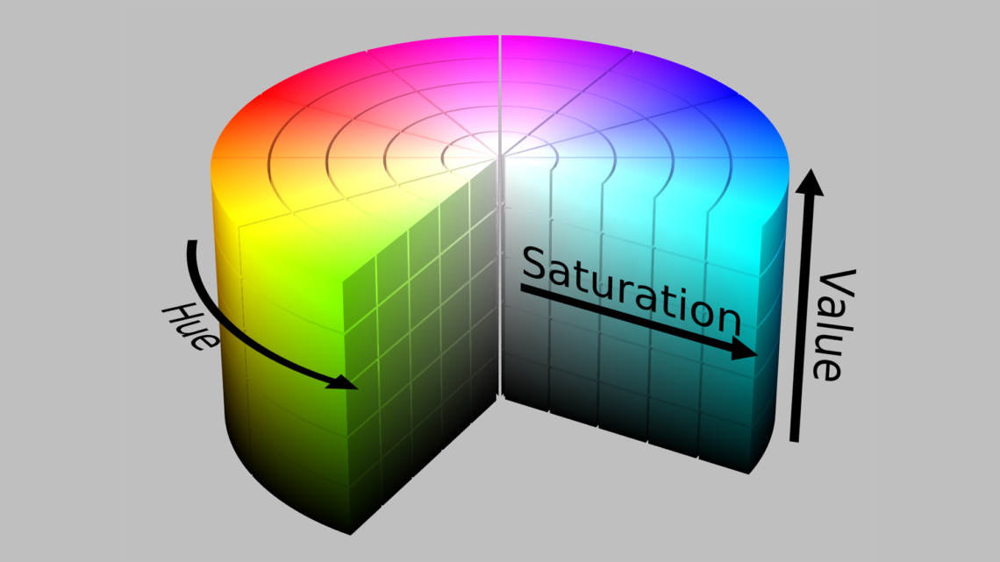

#### **Где используется HSV?**

HSV часто используют в приложениях для редактирования изображений, где пользователю необходимо выбрать цвет или отрегулировать цветовые параметры. Эта модель эффективна для таких задач, поскольку люди довольно хорошо различают оттенки, насыщенность и яркость, что помогает им регулировать цвета более интуитивно, нежели в случае с использованием модели RGB, которая базируется на применении трёх базовых цветов — красного, зелёного и синего, для создания других цветов.

#### **Области применения:**

- **Цифровое искусство и дизайн**: Художники и дизайнеры могут быстро выбирать цвета и оттенки, основываясь на их визуальном восприятии.
- **Анализ данных**: Иногда, для визуализации и анализа данных, может быть полезно использовать разные цвета с разной яркостью и насыщенностью для представления различных значений и категорий данных.
- **Игровая графика**: Разработчики игр могут использовать HSV модель для изменения времени суток в играх, изменения освещения или для создания эффектов мигания и анимации.

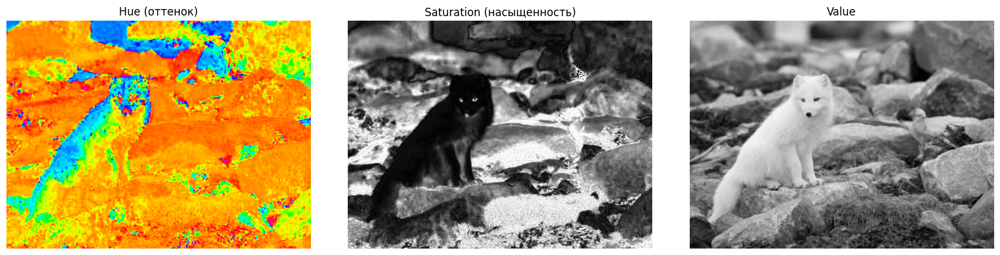

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import matplotlib

hsv_image = cv.cvtColor(img, cv.COLOR_BGR2HSV)

fig, ax = plt.subplots(1, 3, figsize=(16, 8))
fig.tight_layout()

# H: для 8-битного HSV в OpenCV диапазон 0–179
H = hsv_image[:, :, 0]
ax[0].imshow(H, cmap=matplotlib.colormaps['hsv'], vmin=0, vmax=179)
ax[0].set_title("Hue (оттенок)")
ax[0].axis('off')

# S и V: диапазон 0–255
S = hsv_image[:, :, 1]
ax[1].imshow(S, cmap='gray', vmin=0, vmax=255)
ax[1].set_title("Saturation (насыщенность)")
ax[1].axis('off')

V = hsv_image[:, :, 2]
ax[2].imshow(V, cmap='gray', vmin=0, vmax=255)
ax[2].set_title("Value")
ax[2].axis('off')

plt.show()

- **Hue (оттенок):** отображается с помощью цветовой карты спектра "hsv", где каждый пиксель окрашен в соответствующий ему оттенок цвета. Это позволяет визуально определить, какие оттенки присутствуют на изображении и как они распределены.

- **Saturation (насыщенность):** отображается в градациях серого (от чёрного к белому). Светлые области соответствуют высокой насыщенности цвета, тёмные области — низкой. Таким образом, вы можете легко увидеть, где на изображении цвета более насыщенные, а где более бледные.

- **Value (яркость):** также отображается в градациях серого. Более яркие пиксели представляют участки изображения с большей яркостью, тогда как темные пиксели указывают на менее яркие области. Это помогает понять распределение яркости по всему изображению.

### **Цветовое пространство CIELAB (Lab)**

Цветовое пространство CIELAB описывается тремя компонентами:

1. **L\*** (Lightness) — светлота: в теоретическом представлении от 0 (чёрный) до 100 (белый).
2. **a\*** — цветоразностная координата от зелёного к красному.
3. **b\*** — цветоразностная координата от синего к жёлтому.

Для 8-битных изображений OpenCV кодирует Lab в диапазоне 0–255: L* масштабируется, а значения a* и b* получают смещение. Поэтому числовые значения каналов массива OpenCV отличаются от классических диапазонов CIELAB.

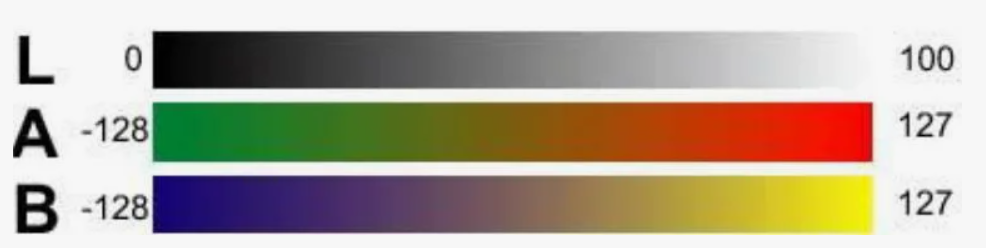

CIELAB является аппаратно-независимым цветовым пространством и используется как удобное промежуточное представление при сравнении и преобразовании цветов. Однако одинаковые координаты Lab сами по себе не гарантируют одинаковое отображение цвета на разных устройствах: результат также зависит от цветового профиля и доступного цветового охвата устройства.

CIELAB применяют в фотографии, полиграфии, дизайне, контроле качества и других задачах, где требуется количественно описывать цвет и цветовые различия.

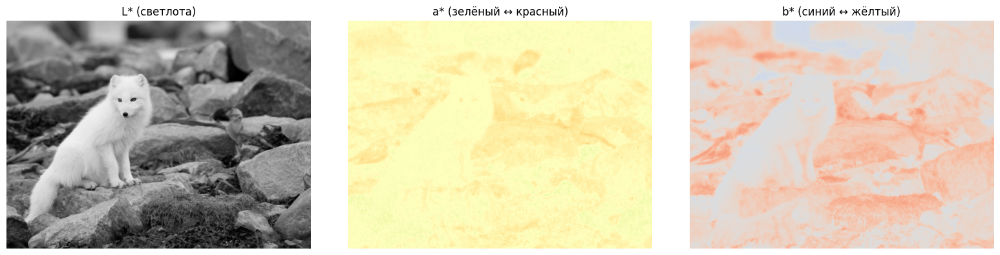

In [ ]:
lab_image = cv.cvtColor(img, cv.COLOR_BGR2LAB)

fig, ax = plt.subplots(1, 3, figsize=(16, 8))
fig.tight_layout()

L = lab_image[:, :, 0]
ax[0].imshow(L, cmap='gray', vmin=0, vmax=255)
ax[0].set_title("L* (светлота)")
ax[0].axis('off')

A = lab_image[:, :, 1]
ax[1].imshow(A, cmap='RdYlGn_r', vmin=0, vmax=255)
ax[1].set_title("a* (зелёный ↔ красный)")
ax[1].axis('off')

B = lab_image[:, :, 2]
ax[2].imshow(B, cmap='coolwarm', vmin=0, vmax=255)
ax[2].set_title("b* (синий ↔ жёлтый)")
ax[2].axis('off')

plt.show()

### **Семейство цветовых пространств YCbCr (YCrCb в OpenCV)**

YCbCr разделяет яркостную составляющую Y и две цветоразностные составляющие Cb и Cr. В OpenCV соответствующее представление называется YCrCb, поскольку каналы хранятся в порядке Y, Cr, Cb.

#### **Компоненты YCrCb**

- **Y** — яркостная составляющая изображения.
- **Cr** — цветоразностная составляющая, связанная с красным компонентом.
- **Cb** — цветоразностная составляющая, связанная с синим компонентом.

Такое разделение позволяет обрабатывать яркостную информацию отдельно от цветовой, что используется, в частности, при сжатии и коррекции изображений.

#### **Преобразование RGB в YCrCb**

Для 8-битного представления можно использовать приближённые соотношения:

- **Y = 0.299 · R + 0.587 · G + 0.114 · B**
- **Cb = (B − Y) · 0.564 + 128**
- **Cr = (R − Y) · 0.713 + 128**

Смещение 128 позволяет хранить цветоразностные компоненты без отрицательных значений в 8-битном массиве.

#### **Субдискретизация цветности**

В форматах хранения и передачи видео цветоразностные компоненты могут иметь меньшее пространственное разрешение, чем Y. Наиболее распространённые обозначения — 4:4:4, 4:2:2 и 4:2:0.

> Представление цветового пространства YCbCr

![Текст ссылки](https://upload.wikimedia.org/wikipedia/commons/b/b8/YCbCr.GIF)

#### **Применение YCrCb**

- **Цифровое телевидение и видео**: YCrCb является стандартом в телевидении и видеосистемах, включая форматы SDTV, HDTV и UHDTV. Стандарты **ITU-R BT.601** и **ITU-R BT.709** определяют параметры этой цветовой модели для разных систем.

- **Сжатие изображений и видео**: В алгоритмах сжатия, таких как JPEG (для изображений) и MPEG, H.264/AVC, HEVC (для видео), YCrCb используется для повышения эффективности сжатия. Разделение яркости и цветности позволяет применять различные методы сжатия к этим компонентам.

- **Обработка изображений**: В компьютерном зрении и обработке изображений YCrCb применяется для улучшения качества изображений, цветокоррекции, сегментации и других задач, где важно отдельно обрабатывать яркость и цвет.

#### **Преимущества модели YCrCb**

- **Эффективность сжатия**: Разделение информации о яркости и цвете позволяет сжимать данные более эффективно, уменьшая объем передаваемых данных без существенной потери воспринимаемого качества.

- **Соответствие особенностям человеческого зрения**: Учитывая, что глаз более чувствителен к яркости, акцент на луминансе обеспечивает лучшее качество изображения при сниженных требованиях к передаче цветовой информации.

- **Совместимость с аналоговыми системами**: YCrCb разработана на основе модели YUV, используемой в аналоговом телевидении, что облегчает совместимость между аналоговыми и цифровыми системами.

Цветовая модель YCrCb играет ключевую роль в современных системах передачи и обработки визуальной информации. Благодаря своему подходу к разделению яркости и цветности она позволяет эффективно сжимать и передавать изображения и видео, сохраняя высокое качество и соответствуя особенностям человеческого восприятия. Ее широкое применение в стандартах телевидения, видео и фотографии делает ее неотъемлемой частью технологий визуальных коммуникаций.

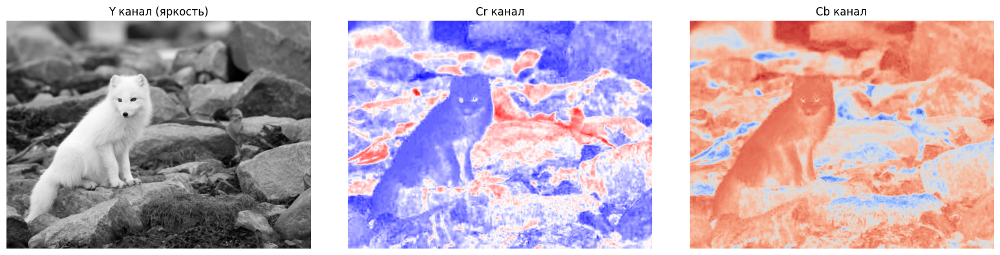

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import matplotlib

YCrCb_image = cv.cvtColor(img, cv.COLOR_BGR2YCrCb)

fig, ax = plt.subplots(1, 3, figsize=(16, 8))
fig.tight_layout()

# Отображение Y-канала (яркость)
Y = YCrCb_image[:, :, 0]
ax[0].imshow(Y, cmap='gray')
ax[0].set_title('Y канал (яркость)')
ax[0].axis('off')

# Отображение Cr-канала (разница между красным и яркостью)
Cr = YCrCb_image[:, :, 1]
Cr_normalized = cv.normalize(Cr, None, alpha=0, beta=255, norm_type=cv.NORM_MINMAX)
# Используем цветовую карту от синего к красному
cmap_cr = matplotlib.colormaps['bwr']
ax[1].imshow(Cr_normalized, cmap=cmap_cr)
ax[1].set_title('Cr канал')
ax[1].axis('off')

# Отображение Cb-канала (разница между синим и яркостью)
Cb = YCrCb_image[:, :, 2]
Cb_normalized = cv.normalize(Cb, None, alpha=0, beta=255, norm_type=cv.NORM_MINMAX)
# Используем цветовую карту от синего к жёлтому
cmap_cb = matplotlib.colormaps['coolwarm']
ax[2].imshow(Cb_normalized, cmap=cmap_cb)
ax[2].set_title('Cb канал')
ax[2].axis('off')

plt.show()

- **Y** отображает яркостную составляющую.
- **Cr**: значения выше нейтрального уровня соответствуют большей положительной красной цветоразностной составляющей.
- **Cb**: значения выше нейтрального уровня соответствуют большей положительной синей цветоразностной составляющей.

Цветовые карты в примере используются только для наглядной визуализации числовых значений каналов.

### **CMYK: Субтративная цветовая модель для печати**

**CMYK** — это субтративная цветовая модель, используемая в основном в полиграфии и печати. Аббревиатура **CMYK** расшифровывается как:

- **C** — **Cyan** (циан)
- **M** — **Magenta** (маджента)
- **Y** — **Yellow** (желтый)
- **K** — **Key** (черный)

CMYK разработана специально для управления цветами в процессе печати, где цвета создаются путем наложения цветных чернил на белую бумагу. В отличие от аддитивной модели **RGB**, используемой в электронных устройствах отображения, таких как мониторы и телевизоры, CMYK работает на основе **субтративного смешения** цветов.

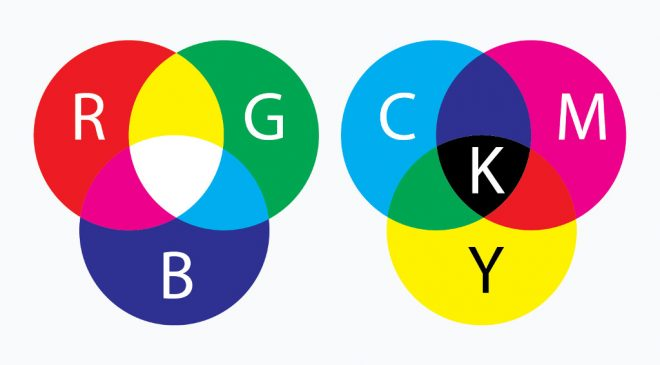

#### **Принципы субтративного смешения цветов**

В субтративной цветовой модели цвета создаются путем **вычитания** определенных длин волн из белого света. Когда свет падает на поверхность, часть его **поглощается** краской, а остальная часть **отражается** и воспринимается глазом.

- **Циан (Cyan)** поглощает **красный** свет и отражает зеленый и синий.
- **Маджента (Magenta)** поглощает **зеленый** свет и отражает красный и синий.
- **Желтый (Yellow)** поглощает **синий** свет и отражает красный и зеленый.

Объединяя эти три цвета в различных пропорциях, можно получить широкий спектр цветов. Однако при наложении циана, мадженты и желтого в максимальной интенсивности получается **темно-коричневый**, а не идеальный черный. Поэтому в модель добавлен отдельный **черный** компонент (**K**), чтобы получить глубокие тени и более насыщенные темные тона.

#### **Компоненты CMYK**

![Текст ссылки](https://i.pinimg.com/736x/49/3e/a9/493ea94acc05c5b7cd7ae26f8fc75058.jpg)

1. **Cyan (Циан)**: Голубоватый цвет, поглощающий красные длины волн. Используется для регулировки интенсивности голубых оттенков в изображении.

2. **Magenta (Маджента)**: Пурпурный цвет, поглощающий зеленые длины волн. Отвечает за насыщенность пурпурных тонов.

3. **Yellow (Желтый)**: Желтый цвет, поглощающий синие длины волн. Контролирует интенсивность желтых оттенков.

4. **Key (Черный)**: Черный цвет, используемый для усиления контраста и глубины темных областей. Позволяет экономить цветные чернила и улучшает резкость изображения.

**Почему буква K?** Буква **K** обозначает "Key" (ключевой цвет), поскольку черный цвет служит основой для контраста и детализации в печатных материалах. Использование буквы **B** (от "Black") может вызвать путаницу с **Blue** (синий) в модели RGB.

#### **Преимущества использования CMYK**

- **Экономия чернил**: Использование черного чернила вместо комбинации циана, мадженты и желтого снижает расход цветных красок.

- **Улучшение качества печати**: ерный пигмент обеспечивает более глубокие тени и четкие контуры.

- **Точное воспроизведение цветов**: CMYK позволяет достичь точного соответствия цветов при печати, учитывая особенности полиграфических процессов.

- **Управление контрастом**: Отдельный черный канал облегчает контроль над контрастностью и детализацией изображения.

#### **Преобразование из RGB в CMYK**

При подготовке изображений для печати необходимо преобразовать их из цветового пространства **RGB** (используемого на экранах) в **CMYK**, поскольку эти модели имеют разные цветовые гаммы.

**Шаги преобразования:**

1. **Нормализация значений RGB**: Преобразуем значения RGB из диапазона [0, 255] в диапазон [0, 1]:

$
   R' = \frac{R}{255},\quad G' = \frac{G}{255},\quad B' = \frac{B}{255}
   $

2. **Вычисление компонента K (черный)**:

$
   K = 1 - \max(R',\ G',\ B')
   $

3. **Вычисление компонентов C, M, Y**:

Если $ K \neq 1 $, то:

$
   C = \frac{1 - R' - K}{1 - K},\quad M = \frac{1 - G' - K}{1 - K},\quad Y = \frac{1 - B' - K}{1 - K}
   $

Если $ K = 1 $, то $ C = M = Y = 0 $.

4. **Масштабирование значений CMYK в диапазон [0, 255]** для хранения и визуализации.

#### **Применение CMYK**

- **Печатная индустрия**: CMYK является стандартом при печати журналов, книг, плакатов, упаковки и других материалов.

- **Графический дизайн**: Дизайнеры используют CMYK для подготовки макетов, предназначенных для печати, чтобы обеспечить точное соответствие цветов.

- **Профилирование устройств**: Настройка принтеров и печатного оборудования для точной передачи цветов в CMYK.

#### **Пример кода для визуализации каналов CMYK**

Ниже представлен пример кода на Python, который преобразует изображение из RGB в CMYK и визуализирует каждый канал отдельно:

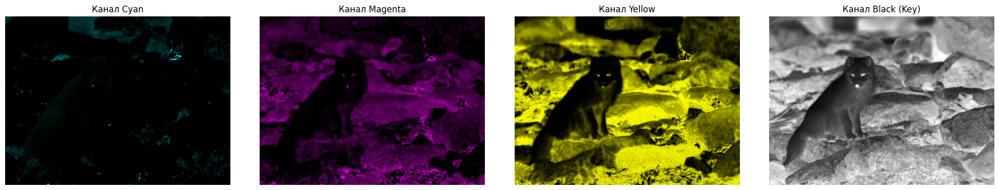

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузка изображения в формате BGR
img_bgr = cv2.imread('arctic_fox.jpg')

# Преобразование изображения в формат RGB
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Нормализация значений RGB в диапазон [0, 1]
img_rgb_norm = img_rgb.astype(float) / 255.0

# Вычисление компонента K (Black Key)
K = 1 - np.max(img_rgb_norm, axis=2)

# Создание маски для пикселей, где K < 1
mask = (K < 1)

# Инициализация компонентов C, M, Y нулями
C = np.zeros_like(K)
M = np.zeros_like(K)
Y = np.zeros_like(K)

# Вычисление компонентов C, M, Y с учетом маски
C[mask] = (1 - img_rgb_norm[:, :, 0][mask] - K[mask]) / (1 - K[mask])
M[mask] = (1 - img_rgb_norm[:, :, 1][mask] - K[mask]) / (1 - K[mask])
Y[mask] = (1 - img_rgb_norm[:, :, 2][mask] - K[mask]) / (1 - K[mask])

# Приведение значений к диапазону [0, 255]
C_disp = (C * 255).astype(np.uint8)
M_disp = (M * 255).astype(np.uint8)
Y_disp = (Y * 255).astype(np.uint8)
K_disp = (K * 255).astype(np.uint8)

# Создание цветных изображений для каждого канала

# Канал Cyan
C_color = np.zeros_like(img_rgb)
C_color[:, :, 1] = C_disp  # Зеленый канал
C_color[:, :, 2] = C_disp  # Синий канал

# Канал Magenta
M_color = np.zeros_like(img_rgb)
M_color[:, :, 0] = M_disp  # Красный канал
M_color[:, :, 2] = M_disp  # Синий канал

# Канал Yellow
Y_color = np.zeros_like(img_rgb)
Y_color[:, :, 0] = Y_disp  # Красный канал
Y_color[:, :, 1] = Y_disp  # Зеленый канал

# Канал Black (Key)
K_color = np.zeros_like(img_rgb)
K_color[:, :, 0] = K_disp  # Красный канал
K_color[:, :, 1] = K_disp  # Зеленый канал
K_color[:, :, 2] = K_disp  # Синий канал

# Отображение каналов CMYK
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
fig.tight_layout()

# Отключаем оси для лучшего отображения
for a in ax:
    a.axis('off')

# Канал Cyan
ax[0].imshow(C_color)
ax[0].set_title('Канал Cyan')

# Канал Magenta
ax[1].imshow(M_color)
ax[1].set_title('Канал Magenta')

# Канал Yellow
ax[2].imshow(Y_color)
ax[2].set_title('Канал Yellow')

# Канал Black (Key)
ax[3].imshow(K_color)
ax[3].set_title('Канал Black (Key)')

plt.show()

**Окраска каналов**: Каждый канал окрашен в соответствующие цвета:
  - **Cyan**: сочетание зелёного и синего каналов.
  - **Magenta**: сочетание красного и синего каналов.
  - **Yellow**: сочетание красного и зелёного каналов.
  - **Black (Key)**: отображается в градациях серого.

Цветовая модель **CMYK** играет важнейшую роль в сфере печати и полиграфии. Она позволяет воспроизводить широкий спектр цветов на физических носителях путем сочетания четырех базовых красок. Понимание принципов работы CMYK и умение преобразовывать изображения из RGB в CMYK являются необходимыми навыками для дизайнеров, фотографов и специалистов по печати.

## **3. Слияние и усиление**

В этом разделе изображение рассматривается как массив NumPy: можно обращаться к отдельным пикселям, изменять их значения и независимо обрабатывать цветовые каналы.

### **Извлечение цветовых компонентов пикселя**

Цветной пиксель содержит три компонента. При загрузке через `cv.imread()` OpenCV использует порядок **BGR**, поэтому значение пикселя имеет вид `[B, G, R]`.

**Рассмотрим пример:**

In [ ]:
import cv2 as cv

img = cv.imread('arctic_fox.jpg')

# Пиксель в строке 10 и столбце 20
b, g, r = img[10, 20]

print("Значения цветовых компонентов пикселя:")
print(f"Синий: {b}, Зелёный: {g}, Красный: {r}")

Значения цветовых компонентов пикселя:
Синий: 168, Зелёный: 158, Красный: 148


Индексация `img[row, col]` сначала задаёт строку, затем столбец. Возвращаемое значение `[b, g, r]` содержит интенсивности трёх каналов.

**Визуализируем положение пикселя:**

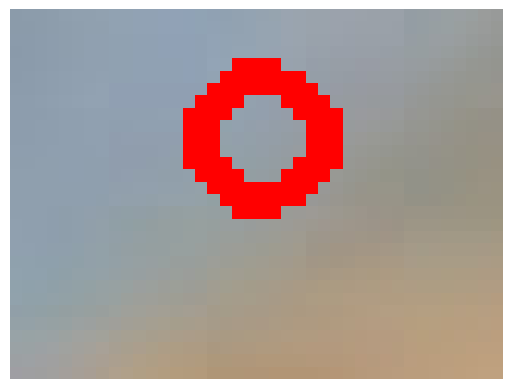

In [ ]:
import matplotlib.pyplot as plt

row, col = 10, 20
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Выделяем выбранный пиксель
cv.circle(img_rgb, (col, row), 5, (255, 0, 0), 2)

fs = 20
fragment = img_rgb[
    max(row - fs, 0):min(row + fs, img.shape[0]),
    max(col - fs, 0):min(col + fs, img.shape[1])
]

plt.imshow(fragment)
plt.axis('off')
plt.show()

### **Изучение структуры изображения**

Свойство `shape` позволяет определить высоту, ширину и количество каналов изображения.

In [ ]:
print("Размеры изображения:")
print(img.shape)

Размеры изображения:
(600, 800, 3)


Для цветного изображения `img.shape` имеет вид `(высота, ширина, 3)`. Три элемента последнего измерения соответствуют каналам B, G и R.

### **Изображение в оттенках серого**

In [ ]:
grayed = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

print("Размеры изображения в оттенках серого:")
print(grayed.shape)

Размеры изображения в оттенках серого:
(600, 800)


Изображение `grayed` является двумерным массивом `(высота, ширина)`: каждый пиксель представлен одним уровнем серого, а не тремя цветовыми компонентами.

#### **Доступ к пикселям изображения в оттенках серого**

In [ ]:
pixel_value = grayed[10, 20]
print(f"Значение пикселя (10, 20): {pixel_value}")

Значение пикселя (10, 20): 156


Для стандартного 8-битного изображения значение уровня серого находится в диапазоне 0–255: 0 соответствует чёрному, 255 — белому.

### **Изменение значений пикселей**

Поскольку изображение является массивом, значения отдельных пикселей или целых областей можно изменять обычной индексацией NumPy.

In [ ]:
# Изменяем пиксель на чистый зелёный цвет в BGR
img_modified = img.copy()
img_modified[10, 20] = [0, 255, 0]

b, g, r = img_modified[10, 20]
print(f"Синий: {b}, Зелёный: {g}, Красный: {r}")

Синий: 0, Зелёный: 255, Красный: 0


### **Разделение и слияние каналов: `cv.split()` и `cv.merge()`**

`cv.split()` разделяет многоканальное изображение на отдельные двумерные массивы, а `cv.merge()` объединяет их обратно.

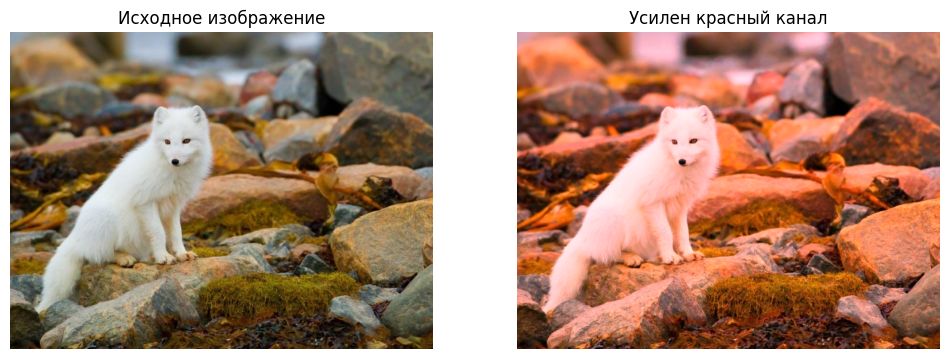

In [ ]:
import numpy as np

b_channel, g_channel, r_channel = cv.split(img)

# Усиливаем красный канал.
# Для 8-битного результата OpenCV ограничивает значения допустимым диапазоном.
r_channel_enhanced = cv.multiply(r_channel, 1.5)

img_enhanced = cv.merge((b_channel, g_channel, r_channel_enhanced))
img_enhanced_rgb = cv.cvtColor(img_enhanced, cv.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax[0].set_title('Исходное изображение')
ax[0].axis('off')

ax[1].imshow(img_enhanced_rgb)
ax[1].set_title('Усилен красный канал')
ax[1].axis('off')

plt.show()

#### **Обнуление одного цветового канала**

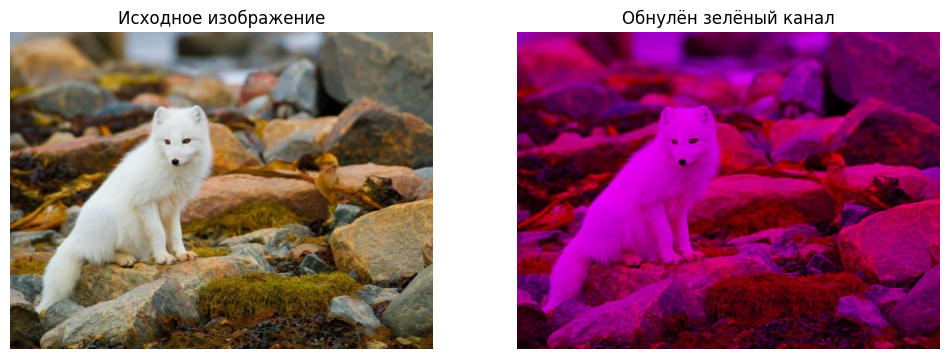

In [ ]:
b_channel, g_channel, r_channel = cv.split(img)

# Удаляем зелёную составляющую
g_channel[:] = 0

img_without_green = cv.merge((b_channel, g_channel, r_channel))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax[0].set_title('Исходное изображение')
ax[0].axis('off')

ax[1].imshow(cv.cvtColor(img_without_green, cv.COLOR_BGR2RGB))
ax[1].set_title('Обнулён зелёный канал')
ax[1].axis('off')

plt.show()

#### **Переполнение `uint8` при арифметических операциях**

Массивы 8-битных изображений обычно имеют тип `uint8` и хранят значения от 0 до 255. При сложении средствами NumPy выход за этот диапазон приводит к циклическому переполнению.

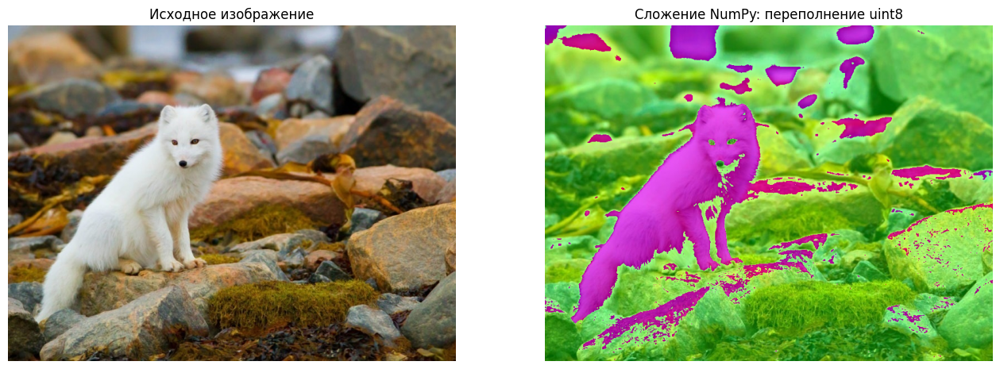

In [ ]:
b, g, r = cv.split(img)

# Намеренно показываем переполнение uint8:
# например, 200 + 100 = 300, а для uint8 результат становится 44.
g_overflow = g + 100

amplified_wrong = cv.merge([b, g_overflow, r])

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax[0].set_title("Исходное изображение")
ax[0].axis('off')

ax[1].imshow(cv.cvtColor(amplified_wrong, cv.COLOR_BGR2RGB))
ax[1].set_title("Сложение NumPy: переполнение uint8")
ax[1].axis('off')

plt.show()

Например, `200 + 100 = 300`, но `uint8` хранит только 0–255, поэтому NumPy получает `300 % 256 = 44`. Из-за этого появляются неожиданные цвета.

#### **Насыщающее сложение `cv.add()`**

`cv.add()` использует насыщающее сложение: значение выше 255 ограничивается числом 255, а не переходит через ноль.

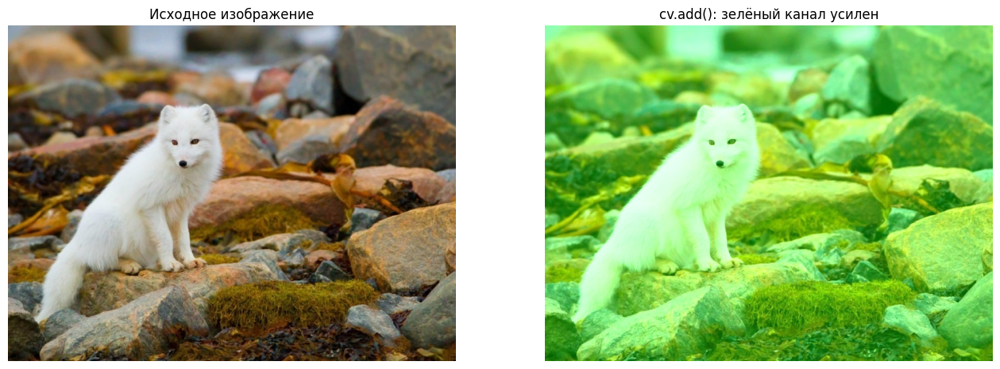

In [ ]:
b, g, r = cv.split(img)

g_amplified = cv.add(g, 100)
amplified = cv.merge([b, g_amplified, r])

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax[0].set_title("Исходное изображение")
ax[0].axis('off')

ax[1].imshow(cv.cvtColor(amplified, cv.COLOR_BGR2RGB))
ax[1].set_title("cv.add(): зелёный канал усилен")
ax[1].axis('off')

plt.show()

#### **Наглядное представление отдельных цветовых каналов**

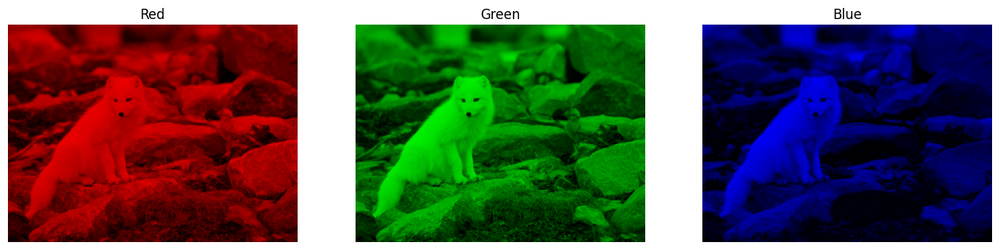

In [ ]:
b, g, r = cv.split(img)
zeros = np.zeros(img.shape[:2], dtype=np.uint8)

blue = cv.merge([b, zeros, zeros])
green = cv.merge([zeros, g, zeros])
red = cv.merge([zeros, zeros, r])

channels = [
    cv.cvtColor(red, cv.COLOR_BGR2RGB),
    cv.cvtColor(green, cv.COLOR_BGR2RGB),
    cv.cvtColor(blue, cv.COLOR_BGR2RGB)
]
titles = ["Red", "Green", "Blue"]

fig, ax = plt.subplots(1, 3, figsize=(16, 8))
for i in range(3):
    ax[i].imshow(channels[i])
    ax[i].set_title(titles[i])
    ax[i].axis('off')

plt.show()

### **Выводы**

Цветное изображение OpenCV — это массив BGR. Индексация позволяет работать с пикселями, `cv.split()` и `cv.merge()` — с отдельными каналами, а при арифметике с `uint8` необходимо учитывать диапазон 0–255 и различие между обычными операциями NumPy и насыщающими операциями OpenCV.

## **4. Работа с гистограммами в OpenCV**

Гистограмма показывает, сколько пикселей приходится на разные значения интенсивности или на значения выбранного цветового канала.

### **Расчёт гистограммы с `cv.calcHist()`**

Основные параметры `cv.calcHist()` задают изображение, индекс анализируемого канала, маску, число интервалов гистограммы и диапазон значений.

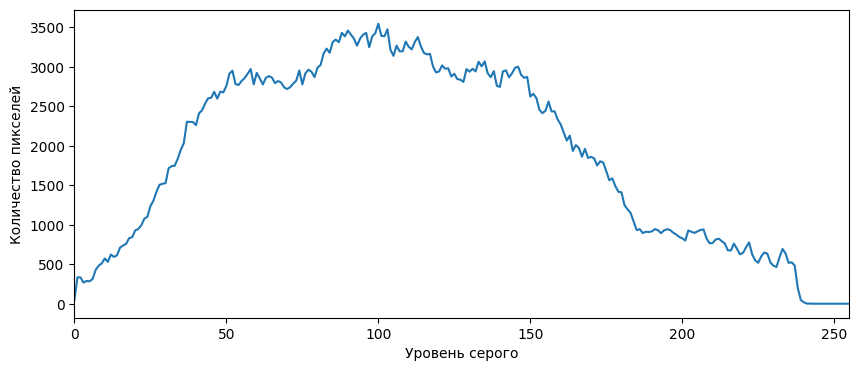

In [ ]:
# Сначала строим гистограмму уровней серого
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

hist = cv.calcHist(
    [gray],     # изображение
    [0],        # единственный канал изображения gray
    None,       # без маски
    [256],      # 256 интервалов
    [0, 256]    # значения 0–255
)

plt.figure(figsize=(10, 4))
plt.plot(hist)
plt.xlim([0, 255])
plt.xlabel("Уровень серого")
plt.ylabel("Количество пикселей")
plt.show()

Здесь `[0]` означает единственный канал изображения `gray`. Если передать цветное BGR-изображение `img`, то `[0]`, `[1]` и `[2]` будут означать соответственно B, G и R. Диапазон `[0, 256]` охватывает 8-битные значения 0–255.

### **Построение гистограммы средствами Matplotlib**

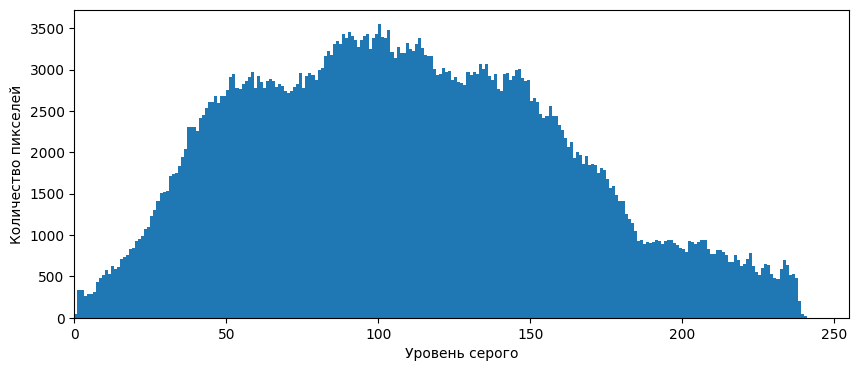

In [ ]:
plt.figure(figsize=(10, 4))
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.xlim([0, 255])
plt.xlabel("Уровень серого")
plt.ylabel("Количество пикселей")
plt.show()

Метод `ravel()` преобразует двумерное изображение в одномерный массив значений. Для цветного BGR-изображения `img.ravel()` смешал бы значения всех трёх каналов, поэтому такой график нельзя интерпретировать как гистограмму яркости.

### **Гистограммы отдельных цветовых каналов**

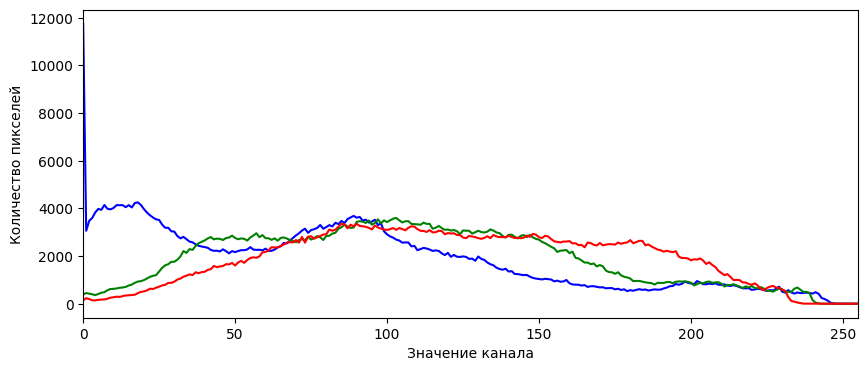

In [ ]:
colors = ('b', 'g', 'r')

plt.figure(figsize=(10, 4))
for i, color in enumerate(colors):
    hist_channel = cv.calcHist([img], [i], None, [256], [0, 256])
    plt.plot(hist_channel, color=color)

plt.xlim([0, 255])
plt.xlabel("Значение канала")
plt.ylabel("Количество пикселей")
plt.show()

Такие три кривые показывают распределения значений B, G и R отдельно. Они описывают цветовые каналы, а не единую яркостную характеристику изображения.

### **Отображение BGR-изображения в Matplotlib**

Matplotlib интерпретирует трёхканальный массив как RGB, тогда как `cv.imread()` возвращает BGR. Поэтому перед `imshow()` изображение OpenCV обычно преобразуют из BGR в RGB.

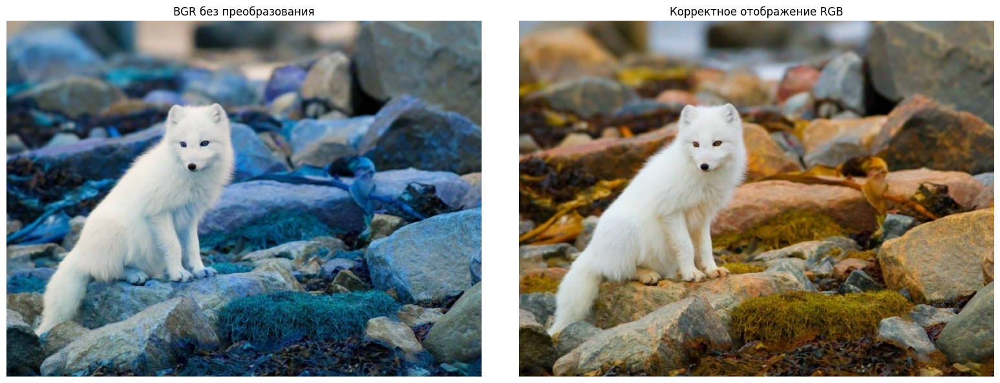

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
fig.tight_layout()

ax[0].imshow(img)
ax[0].set_title("BGR без преобразования")
ax[0].axis('off')

ax[1].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax[1].set_title("Корректное отображение RGB")
ax[1].axis('off')

plt.show()

### **Выравнивание гистограммы**

Выравнивание гистограммы — преобразование уровней интенсивности на основе их кумулятивного распределения. Цель состоит в более эффективном использовании доступного диапазона и повышении контраста, а не в получении идеально равномерной гистограммы.

Глобальное выравнивание полезно, когда значительная часть значений сосредоточена в узком диапазоне. Если изображение уже содержит одновременно очень тёмные и очень светлые области, глобальная коррекция может ухудшить отдельные участки или усилить шум.

### **Загрузка изображения для примера**

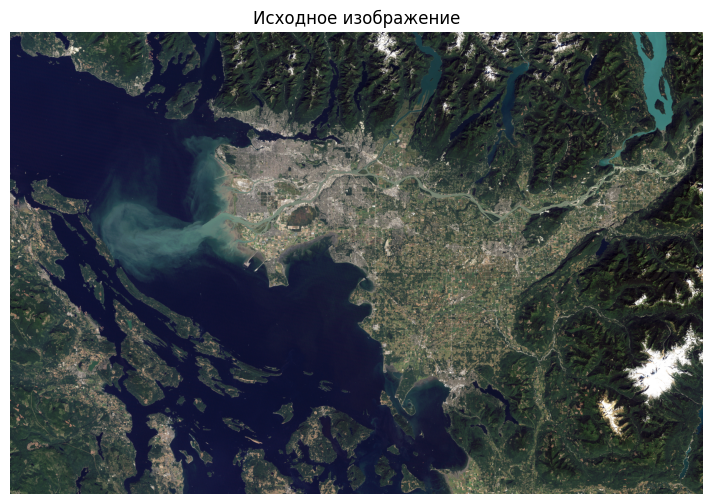

In [ ]:
import requests
from io import BytesIO

url = 'https://eoimages.gsfc.nasa.gov/images/imagerecords/77000/77368/vancouver_tm5_2011250_lrg.jpg'

response = requests.get(url)
response.raise_for_status()

img_bytes = np.frombuffer(response.content, dtype=np.uint8)
image = cv.imdecode(img_bytes, cv.IMREAD_COLOR)

plt.figure(figsize=(12, 6))
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("Исходное изображение")
plt.axis('off')
plt.show()

### **Функция для анализа яркостной гистограммы**

Для цветного изображения функция ниже анализирует канал **Y** пространства YCrCb. Поэтому среднее, минимум, максимум и гистограмма относятся именно к яркостной составляющей, а не к смеси B, G и R.

In [ ]:
def img2hist(temp_img, label=True):
    # Для цветного изображения анализируем яркостный канал Y.
    if temp_img.ndim == 3:
        values = cv.cvtColor(temp_img, cv.COLOR_BGR2YCrCb)[:, :, 0]
        channel_name = "Y"
    else:
        values = temp_img
        channel_name = "уровня серого"

    if label:
        print(f"Среднее значение {channel_name}: {values.mean():.2f}")
        print(f"Минимум: {values.min()}")
        print(f"Максимум: {values.max()}")

    plt.figure(figsize=(10, 4))
    plt.hist(values.ravel(), bins=256, range=(0, 256))
    plt.xlim([0, 255])
    plt.xlabel("Интенсивность")
    plt.ylabel("Количество пикселей")

Нулевые значения не удаляются: они являются полноценной частью распределения и могут нести важную информацию о тёмных областях изображения.

### **Гистограмма исходного изображения**

Среднее значение Y: 58.16
Минимум: 0
Максимум: 255


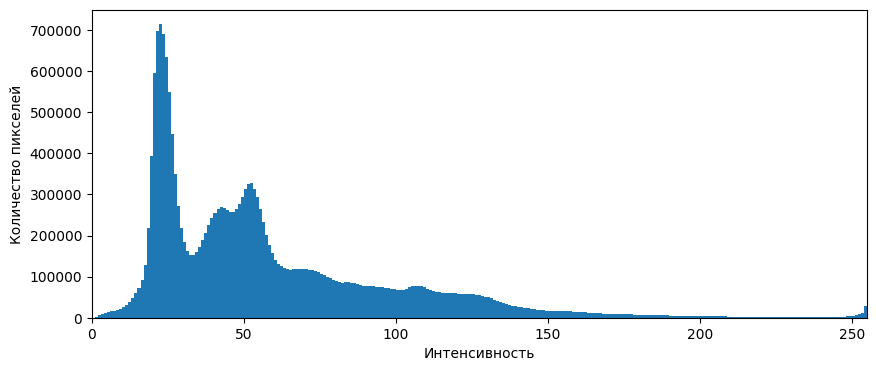

In [ ]:
img2hist(image)
plt.show()

### **Глобальное выравнивание: `cv.equalizeHist()`**

`cv.equalizeHist()` принимает 8-битное одноканальное изображение. Алгоритм рассчитывает гистограмму, строит её кумулятивное распределение, нормирует его к доступному диапазону и использует полученное соответствие как таблицу преобразования уровней интенсивности.

Для цветного изображения не следует независимо выравнивать каналы B, G и R: это может изменить цветовой баланс. Удобнее перейти в пространство, где яркостная составляющая отделена от цветоразностных, и изменить только её.

#### **Выравнивание канала Y в YCrCb**

In [ ]:
ycrcb_img = cv.cvtColor(image, cv.COLOR_BGR2YCrCb)

# Изменяем только яркостный канал Y
ycrcb_equalized = ycrcb_img.copy()
ycrcb_equalized[:, :, 0] = cv.equalizeHist(ycrcb_equalized[:, :, 0])

equalized_img = cv.cvtColor(ycrcb_equalized, cv.COLOR_YCrCb2BGR)

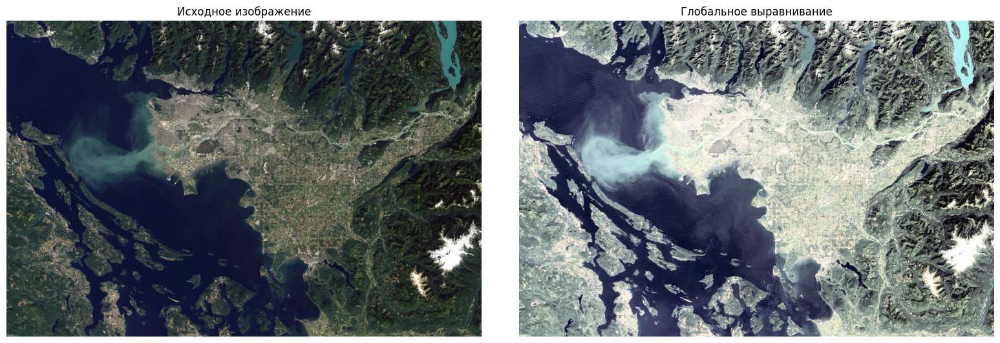

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
fig.tight_layout()

ax[0].imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
ax[0].set_title("Исходное изображение")
ax[0].axis('off')

ax[1].imshow(cv.cvtColor(equalized_img, cv.COLOR_BGR2RGB))
ax[1].set_title("Глобальное выравнивание")
ax[1].axis('off')

plt.show()

### **Гистограммы до и после глобального выравнивания**

Среднее значение Y: 58.16
Минимум: 0
Максимум: 255


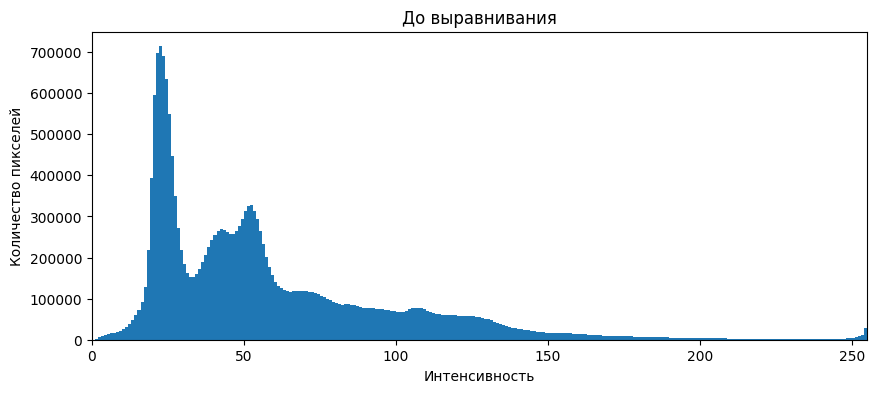

Среднее значение Y: 129.10
Минимум: 0
Максимум: 255


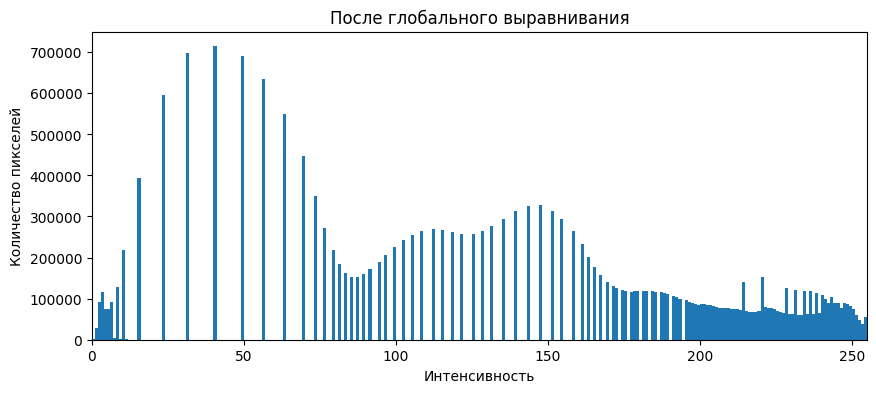

In [ ]:
img2hist(image)
plt.title("До выравнивания")
plt.show()

img2hist(equalized_img)
plt.title("После глобального выравнивания")
plt.show()

После `equalizeHist()` яркостные значения обычно занимают более широкий диапазон, но итоговая гистограмма не обязана быть равномерной, а среднее значение яркости не обязано увеличиваться. Оценивать результат следует по распределению, деталям и возможному клиппингу.

### **Как интерпретировать форму гистограммы**

- Скопление значений слева означает большое количество тёмных пикселей; это может быть особенностью сцены и само по себе не доказывает недоэкспонирование.
- Скопление справа означает большое количество светлых пикселей; это также не обязательно является переэкспонированием.
- Узкая гистограмма часто указывает на ограниченный тональный диапазон и невысокий контраст.
- Широкая гистограмма означает использование большого диапазона значений, но не гарантирует хорошее качество изображения.
- Выраженные пики показывают, что определённые уровни интенсивности встречаются часто.
- Сильное скопление непосредственно у 0 или 255 может указывать на потерю деталей в тенях или светах, если это не обусловлено самой сценой.

### **Адаптивное выравнивание с ограничением контраста: CLAHE**

CLAHE выполняет выравнивание локально. Изображение делится на фиксированную сетку прямоугольных областей (`tiles`), для каждой области рассчитывается собственное преобразование гистограммы, а чрезмерное усиление ограничивается параметром `clipLimit`.

#### **Параметры `cv.createCLAHE()`**

- **`clipLimit`** ограничивает высоту пиков локальной гистограммы перед перераспределением отсечённых значений. Чем меньше ограничение, тем сильнее подавляется чрезмерное локальное усиление.
- **`tileGridSize=(8, 8)`** означает **8 областей по горизонтали и 8 по вертикали**, то есть всего 64 области. Это **не окно размером 8×8 пикселей и не скользящее окно**.

Например, для изображения 800×600 пикселей сетка `(8, 8)` даёт области примерно 100×75 пикселей. Если размеры изображения не делятся на число областей без остатка, OpenCV служебно дополняет границы так, чтобы сформировать сетку.

После расчёта локальных преобразований OpenCV плавно интерполирует результаты соседних областей. Благодаря этому на изображении не появляются резкие границы между плитками.

Увеличение `tileGridSize`, например с `(8, 8)` до `(16, 16)`, создаёт больше областей меньшего размера и делает обработку более локальной. Уменьшение числа областей, наоборот, делает коррекцию более глобальной.

#### **Когда применять CLAHE**

CLAHE полезен, когда освещение или контраст заметно различаются в разных частях изображения. Он применяется в задачах улучшения локальной видимости деталей, предварительной обработки и анализа изображений.

In [ ]:
ycrcb_img = cv.cvtColor(image, cv.COLOR_BGR2YCrCb)

# (8, 8) — это 8 плиток по ширине × 8 по высоте, а не окно 8×8 пикселей.
clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

ycrcb_clahe = ycrcb_img.copy()
ycrcb_clahe[:, :, 0] = clahe.apply(ycrcb_clahe[:, :, 0])

clahe_eq_img = cv.cvtColor(ycrcb_clahe, cv.COLOR_YCrCb2BGR)

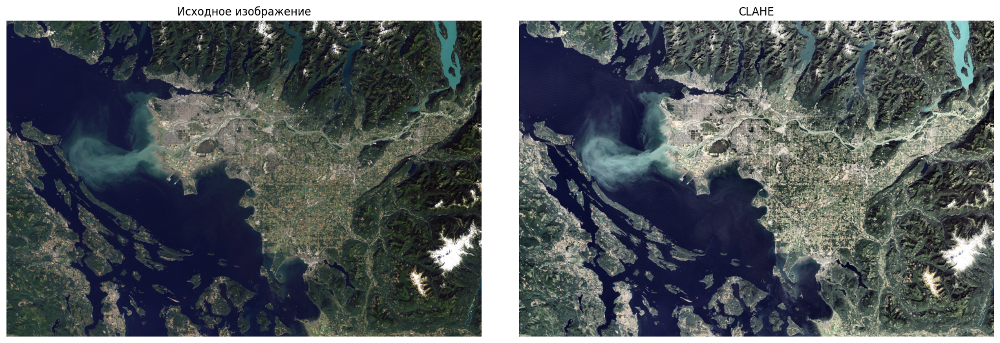

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
fig.tight_layout()

ax[0].imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
ax[0].set_title("Исходное изображение")
ax[0].axis('off')

ax[1].imshow(cv.cvtColor(clahe_eq_img, cv.COLOR_BGR2RGB))
ax[1].set_title("CLAHE")
ax[1].axis('off')

plt.show()

### **Гистограммы до и после CLAHE**

Среднее значение Y: 58.16
Минимум: 0
Максимум: 255


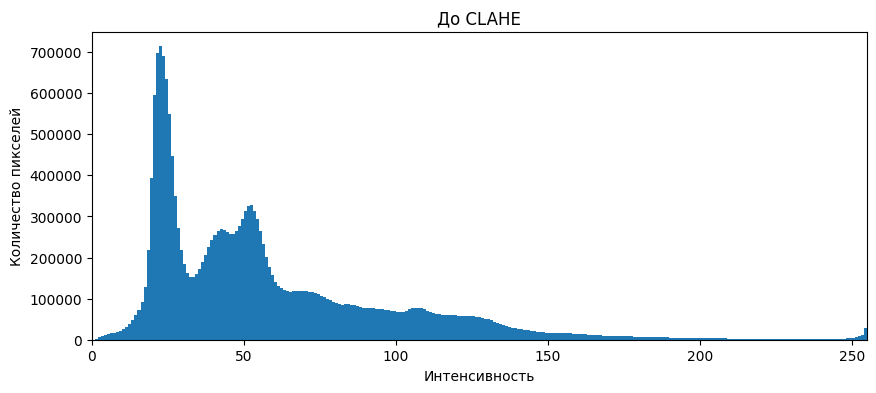

Среднее значение Y: 86.66
Минимум: 0
Максимум: 255


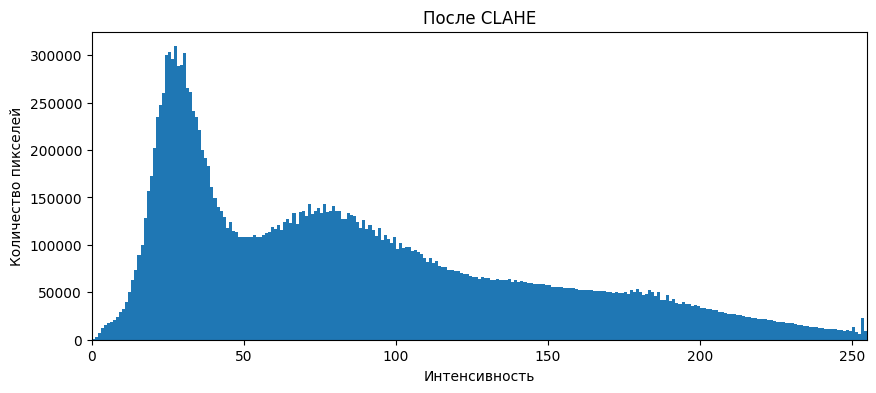

In [ ]:
img2hist(image)
plt.title("До CLAHE")
plt.show()

img2hist(clahe_eq_img)
plt.title("После CLAHE")
plt.show()

CLAHE оптимизирует локальный контраст, поэтому его глобальная гистограмма не должна стремиться к равномерному или нормальному распределению. Результат зависит от содержимого изображения, `clipLimit` и размера сетки.

### **Выводы**

Гистограмма позволяет анализировать распределение значений изображения. Для цветных изображений важно различать гистограммы B/G/R и гистограмму яркостной составляющей. `cv.equalizeHist()` выполняет глобальное преобразование одноканального изображения, а CLAHE корректирует контраст локально с ограничением чрезмерного усиления.

При работе с цветным изображением коррекцию контраста целесообразно выполнять по яркостному каналу, сохраняя цветоразностные компоненты. Параметр `tileGridSize` в CLAHE задаёт количество областей сетки, а не размер скользящего окна.